# 3. Modeling

**Question:** using only information known at upload time, can we predict whether a video beats its channel's typical views?

- Target: `popular` (1 = more views than the same channel's median for that quarter)
- Models: baseline → logistic regression → LightGBM → **title words (TF-IDF)** → **blend**
- Split **by time** into train / validation / test

## Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import lightgbm as lgb
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay

videos = pd.read_csv("videos_features.csv", parse_dates=["published_at"])

# Listed by hand so likes, comments and views can never sneak in
features = ["title_length", "title_words", "title_caps_ratio", "title_has_number",
            "title_has_question", "title_has_exclaim", "title_has_emoji",
            "duration_min", "publish_hour", "publish_weekday",
            "num_tags", "description_length", "description_links", "days_since_last_upload"]
target = "popular"

## Train / validation / test split (by time)

| Set | Quarters | Used for |
|---|---|---|
| Train | all older quarters | fitting the models |
| **Validation** | second-newest quarter | **choosing** the best model |
| **Test** | newest quarter | the final score, looked at **once** |

**Why a validation set?** If we picked the best model by its test score, the test score would be optimistic: we'd have tuned to it.
Choosing on validation keeps the test set honest.

A random split would train on future videos, so every split is by time. Splits fall exactly on quarter boundaries, so no quarter's median is shared between sets.

In [2]:
quarters = sorted(videos["quarter"].unique())
valid_quarter, test_quarter = quarters[-2], quarters[-1]

train = videos[videos["quarter"] < valid_quarter]
valid = videos[videos["quarter"] == valid_quarter]
test = videos[videos["quarter"] == test_quarter]

for name, part in [("Train", train), ("Validation", valid), ("Test", test)]:
    print(f"{name:10s} {len(part):5d} videos  {part['quarter'].min()} to {part['quarter'].max()}  popular rate {part[target].mean():.3f}")

Train       2498 videos  2024Q4 to 2026Q1  popular rate 0.491
Validation   846 videos  2026Q2 to 2026Q2  popular rate 0.492
Test         877 videos  2026Q3 to 2026Q3  popular rate 0.494


## Models

- **Baseline:** always predict the most common class. Every model must beat this.
- **Logistic regression:** simple and explainable; `StandardScaler` puts features on the same scale.
- **LightGBM:** learns combinations and thresholds (e.g. "long videos do well, but only on weekends").
  Small trees and `min_child_samples=30` keep it from overfitting.
- **Title words (TF-IDF):** uses the actual **words** in the title and tags, which capture the video's topic.
- **Blend:** the average of the LightGBM and title-words probabilities, combining *how* a video is packaged with *what* it's about.

### What is TF-IDF?

It turns text into numbers, one column per word (or two-word phrase):
- **TF (term frequency):** does the word appear in this title?
- **IDF (inverse document frequency):** rare words count more than words that appear everywhere ("video", "the").

A logistic regression then learns which words go with popular videos.
`min_df=5` ignores words used in fewer than 5 videos, and the vocabulary is learned from the **training videos only**, so nothing from the evaluation period leaks in.

Every model is wrapped in one function, so the exact same code runs on validation and on test.

In [3]:
def title_text(df):
    return df["title"].fillna("") + " " + df["tags"].fillna("").str.replace("|", " ")


def fit_and_predict(train_df, eval_df):
    """Fit every model on train_df and return its predicted probability of 'popular' for eval_df."""
    probs = {"Baseline": np.full(len(eval_df), float(train_df[target].mode()[0]))}

    logreg = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
    probs["Logistic regression"] = logreg.fit(train_df[features], train_df[target]).predict_proba(eval_df[features])[:, 1]

    lgbm = lgb.LGBMClassifier(n_estimators=300, learning_rate=0.03, num_leaves=15,
                              min_child_samples=30, random_state=42, verbose=-1)
    probs["LightGBM"] = lgbm.fit(train_df[features], train_df[target]).predict_proba(eval_df[features])[:, 1]

    tfidf = TfidfVectorizer(min_df=5, ngram_range=(1, 2), sublinear_tf=True)
    words_train = tfidf.fit_transform(title_text(train_df))      # vocabulary learned from training videos only
    words_eval = tfidf.transform(title_text(eval_df))
    words_model = LogisticRegression(C=0.5, max_iter=2000)
    probs["Title words (TF-IDF)"] = words_model.fit(words_train, train_df[target]).predict_proba(words_eval)[:, 1]

    probs["Blend (LightGBM + title words)"] = (probs["LightGBM"] + probs["Title words (TF-IDF)"]) / 2
    return probs, lgbm, tfidf, words_model


def score_table(probs, y):
    rows = []
    for name, prob in probs.items():
        pred = (prob >= 0.5).astype(int)
        rows.append({"Model": name,
                     "Accuracy": round(accuracy_score(y, pred), 3),
                     "F1": round(f1_score(y, pred), 3) if name != "Baseline" else None,
                     "ROC-AUC": round(roc_auc_score(y, prob), 3) if name != "Baseline" else 0.5})
    return pd.DataFrame(rows)

## Step 1: choose the model on the validation quarter

- **Accuracy:** share of correct predictions (fair here, because the classes are balanced ~50/50)
- **F1:** balance of precision (when it says "popular", is it right?) and recall (does it find the popular videos?)
- **ROC-AUC:** how well the model *ranks* videos from most to least likely to be popular. 0.5 = random, 1.0 = perfect.
  This is the number used to choose.

In [4]:
valid_probs, *_ = fit_and_predict(train, valid)
valid_results = score_table(valid_probs, valid[target])

best_model = valid_results.loc[valid_results["ROC-AUC"].idxmax(), "Model"]
print("Chosen on validation:", best_model)
valid_results

Chosen on validation: Blend (LightGBM + title words)


,Model,Accuracy,F1,ROC-AUC
0,Baseline,0.508,NaN,0.500
1,Logistic regression,0.580,0.509,0.581
2,LightGBM,0.609,0.596,0.659
3,Title words (TF-IDF),0.583,0.524,0.652
4,Blend (LightGBM + title words),0.609,0.572,0.669


## Step 2: final test, evaluated once

Retrain on train + validation (all data before the test quarter), then score the newest quarter.
The chosen model was fixed in Step 1; all models are shown for comparison.

In [5]:
train_full = pd.concat([train, valid])
test_probs, lgbm, tfidf, words_model = fit_and_predict(train_full, test)
test_results = score_table(test_probs, test[target])

print("Chosen model:", best_model)
test_results

Chosen model: Blend (LightGBM + title words)


,Model,Accuracy,F1,ROC-AUC
0,Baseline,0.506,NaN,0.500
1,Logistic regression,0.536,0.440,0.538
2,LightGBM,0.580,0.552,0.650
3,Title words (TF-IDF),0.611,0.596,0.655
4,Blend (LightGBM + title words),0.623,0.605,0.677


## What the models learned

**Left:** confusion matrix of the chosen model. **Middle:** which numeric features LightGBM relies on.
**Right:** title/tag words most strongly linked to beating (orange) or missing (blue) the channel's median.

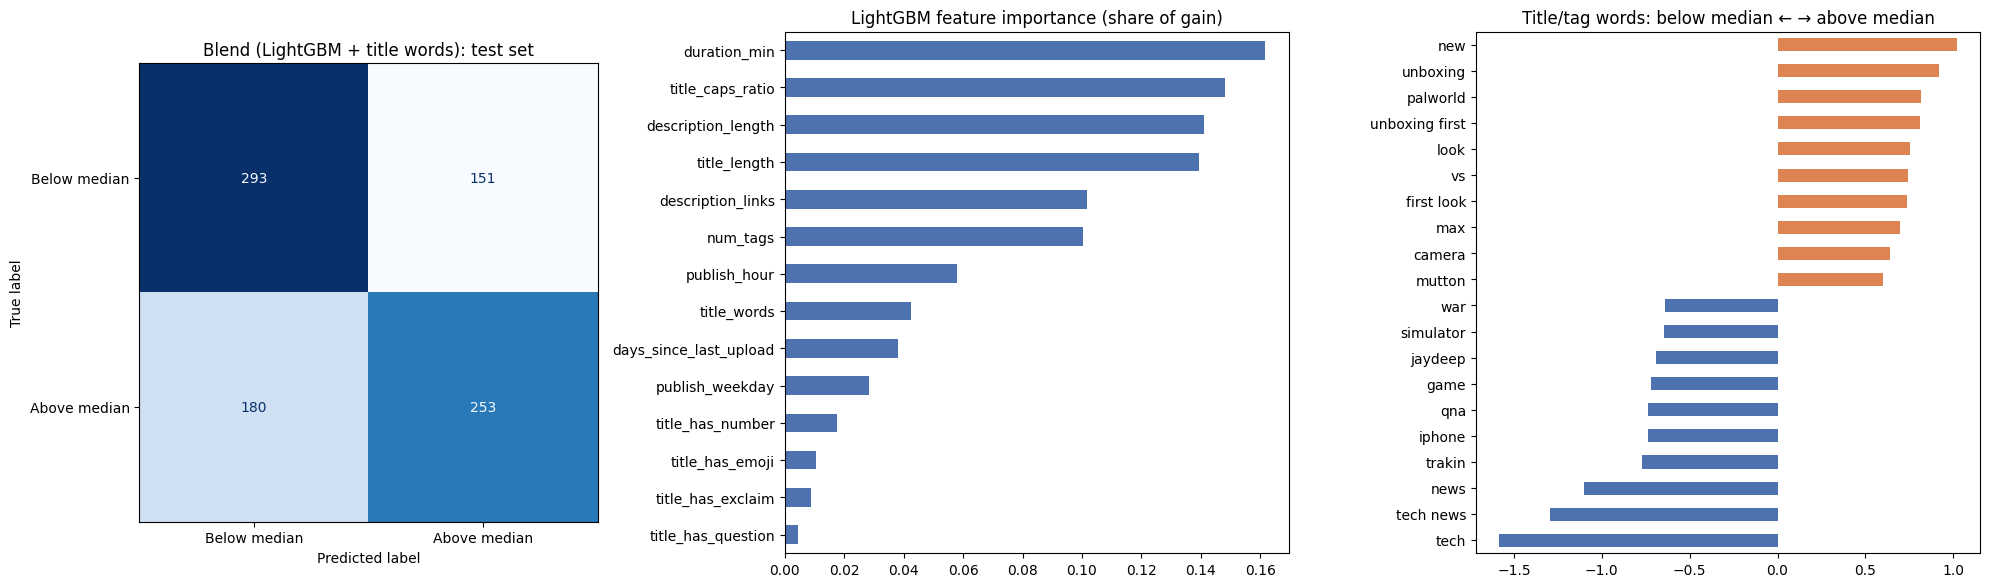

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(20, 6), gridspec_kw={"width_ratios": [1, 1.1, 1.1]})

best_pred = (test_probs[best_model] >= 0.5).astype(int)
ConfusionMatrixDisplay(confusion_matrix(test[target], best_pred),
                       display_labels=["Below median", "Above median"]).plot(ax=axes[0], cmap="Blues", colorbar=False)
axes[0].set_title(f"{best_model}: test set")

importance = pd.Series(lgbm.booster_.feature_importance("gain"), index=features)
(importance / importance.sum()).sort_values().plot.barh(ax=axes[1], color="#4C72B0")
axes[1].set_title("LightGBM feature importance (share of gain)")

weights = pd.Series(words_model.coef_[0], index=tfidf.get_feature_names_out()).sort_values()
top_words = pd.concat([weights.head(10), weights.tail(10)])
top_words.plot.barh(ax=axes[2], color=["#4C72B0"] * 10 + ["#DD8452"] * 10)
axes[2].set_title("Title/tag words: below median ← → above median")

plt.tight_layout()
plt.show()

## Leakage check

Train the chosen model on **shuffled** labels. If it still scored well, something other than the features would be giving away the answer.
It should land near 0.5.

In [7]:
shuffled = train_full.copy()
shuffled[target] = shuffled[target].sample(frac=1, random_state=0).values
shuffled_probs, *_ = fit_and_predict(shuffled, test)

print(f"ROC-AUC of {best_model}")
print("  real labels:    ", round(roc_auc_score(test[target], test_probs[best_model]), 3))
print("  shuffled labels:", round(roc_auc_score(test[target], shuffled_probs[best_model]), 3))

ROC-AUC of Blend (LightGBM + title words)
  real labels:     0.677
  shuffled labels: 0.464


## Conclusion

| Model | Validation ROC-AUC | Test accuracy | Test ROC-AUC |
|---|---|---|---|
| Baseline | 0.500 | 0.506 | 0.500 |
| Logistic regression | 0.581 | 0.536 | 0.538 |
| LightGBM | 0.659 | 0.580 | 0.650 |
| Title words (TF-IDF) | 0.652 | 0.611 | 0.655 |
| **Blend (chosen on validation)** | **0.669** | **0.623** | **0.677** |

- **The blend was chosen on the validation quarter, and the test quarter confirms it:** 62.3% accuracy and ROC-AUC 0.68, versus 50.6% for the baseline.
  With shuffled labels the same model falls to ~0.5, so the signal is real.
- **The words matter more than title statistics.** On their own, title/tag words beat the 14 numeric features on test, because they capture the video's **topic**.
- **Topic patterns:** new-product videos ("unboxing", "first look", "new", "vs", "camera") beat their channel's usual views, while routine formats ("tech news", "news", "Q&A") fall below.
  Some top words are channel names, meaning the model also learns each channel's regular formats.
- **Most useful numeric features:** video length, share of capital letters in the title, description and title length.
- **Confusion matrix:** when the model predicts "popular" it is right 63% of the time, and it finds 58% of the popular videos (253 of 433).
- **Takeaway:** upload-time information explains part of a video's success. The biggest remaining drivers (thumbnail, trends, the algorithm) aren't in the metadata.

**Next steps:** thumbnail image features, pretrained text embeddings instead of TF-IDF, and more channels per niche.